In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Real-World Telco Customer Churn Dataset එක Load කිරීම
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("--- Dataset Shape (Rows, Columns) ---")
print(df.shape)

print("\n--- First 5 Rows ---")
print(df.head())

# 2. Data Cleaning & Preprocessing
df_clean = df.copy()

# 'TotalCharges' column එක text (object) ලෙස ඇති නිසා numeric බවට හැරවීම
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")

print("\n--- Missing Values Before Cleaning ---")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# හිස් අගයන් (11 rows) Median අගයෙන් පිරවීම සහ අනවශ්‍ය customerID ඉවත් කිරීම
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(df_clean["TotalCharges"].median())
df_clean.drop(columns=["customerID"], inplace=True)

# Target column එක ('Churn') binary (0, 1) බවට හැරවීම
df_clean["Churn_Numeric"] = df_clean["Churn"].map({"No": 0, "Yes": 1})

print("\n--- Missing Values After Cleaning ---")
print(df_clean.isnull().sum().sum(), "missing values remaining!")

print("\n--- Numerical Summary Statistics ---")
print(df_clean[["tenure", "MonthlyCharges", "TotalCharges", "Churn_Numeric"]].describe().round(2))

--- Dataset Shape (Rows, Columns) ---
(7043, 21)

--- First 5 Rows ---
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...             

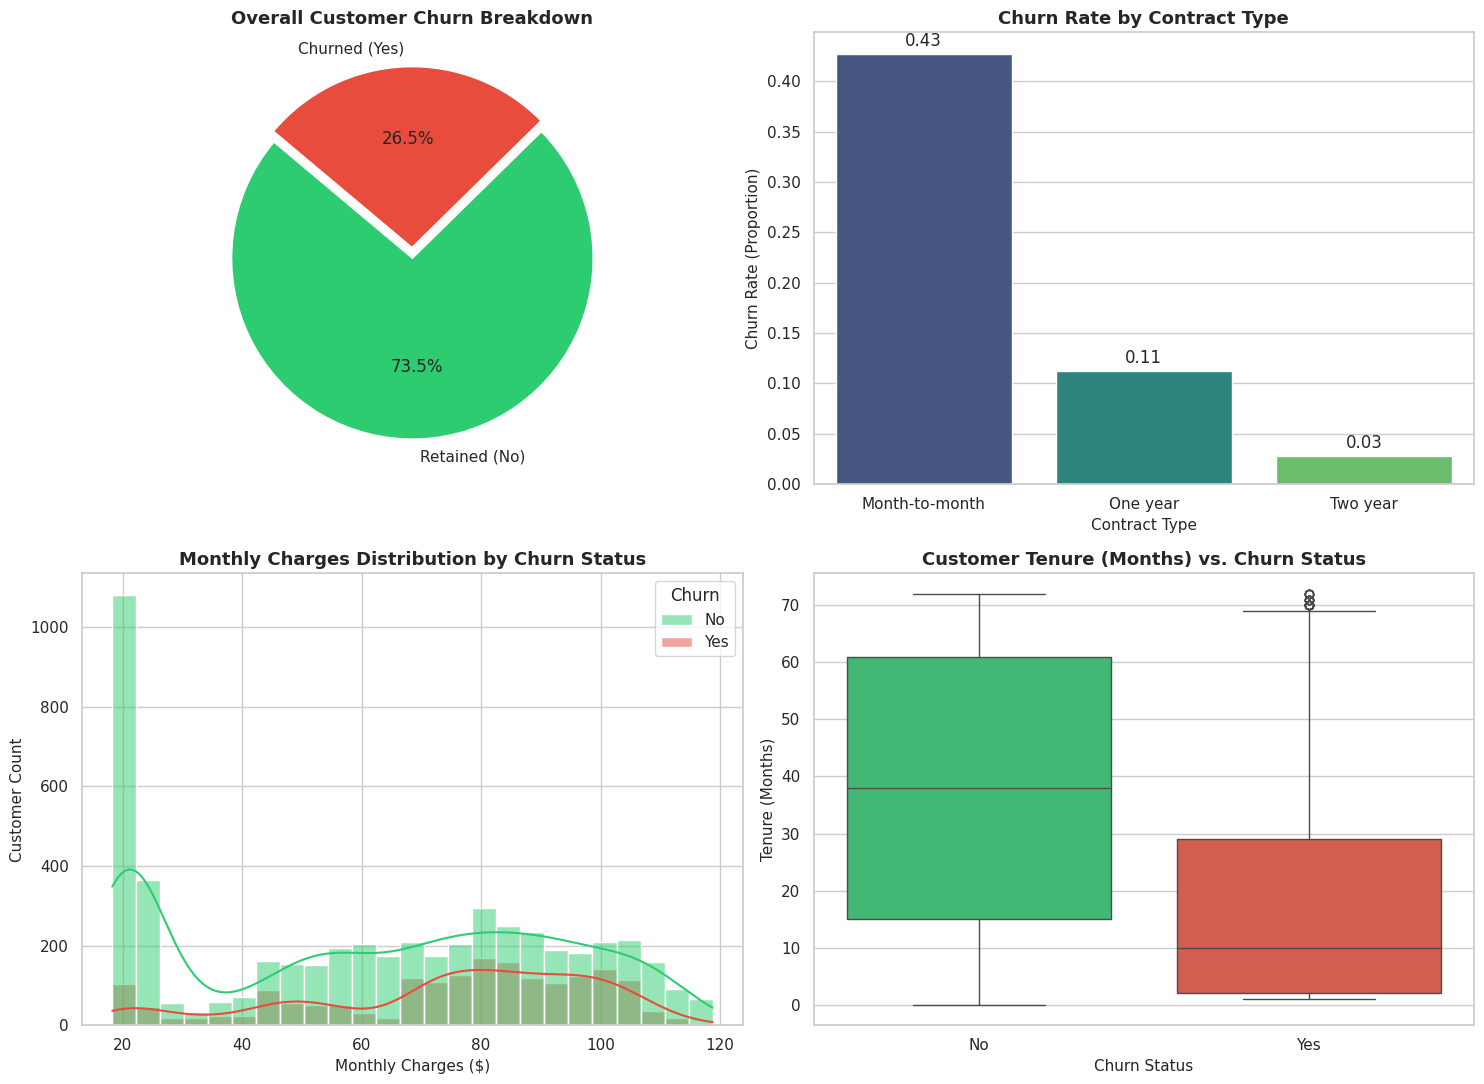

--- Key Business Insights ---
Overall Churn Rate: 26.54%

Churn Rate by Contract Type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn_Numeric, dtype: float64

Average Monthly Charges (Retained vs Churned):
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Dataset එක load කර clean කරගැනීම (Self-contained cell)
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_clean = pd.read_csv(url)
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(df_clean["TotalCharges"].median())
df_clean.drop(columns=["customerID"], inplace=True)
df_clean["Churn_Numeric"] = df_clean["Churn"].map({"No": 0, "Yes": 1})

# --- 2x2 Business EDA Dashboard නිර්මාණය කිරීම ---
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Overall Customer Churn Breakdown (Pie Chart)
churn_counts = df_clean["Churn"].value_counts()
axes[0, 0].pie(
    churn_counts,
    labels=["Retained (No)", "Churned (Yes)"],
    autopct="%1.1f%%",
    startangle=140,
    colors=["#2ecc71", "#e74c3c"],
    explode=[0, 0.06]
)
axes[0, 0].set_title("Overall Customer Churn Breakdown", fontsize=13, fontweight="bold")

# 2. Churn Rate by Contract Type (Bar Chart)
contract_churn = df_clean.groupby("Contract")["Churn_Numeric"].mean().reset_index()
sns.barplot(
    data=contract_churn,
    x="Contract",
    y="Churn_Numeric",
    hue="Contract",
    palette="viridis",
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Churn Rate by Contract Type", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("Contract Type", fontsize=11)
axes[0, 1].set_ylabel("Churn Rate (Proportion)", fontsize=11)
for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container, fmt="%.2f", padding=3)

# 3. Monthly Charges Distribution by Churn Status (Histogram + KDE)
sns.histplot(
    data=df_clean,
    x="MonthlyCharges",
    hue="Churn",
    bins=25,
    kde=True,
    palette={"No": "#2ecc71", "Yes": "#e74c3c"},
    ax=axes[1, 0]
)
axes[1, 0].set_title("Monthly Charges Distribution by Churn Status", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Monthly Charges ($)", fontsize=11)
axes[1, 0].set_ylabel("Customer Count", fontsize=11)

# 4. Customer Tenure by Churn Status (Boxplot)
sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette={"No": "#2ecc71", "Yes": "#e74c3c"},
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Customer Tenure (Months) vs. Churn Status", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("Churn Status", fontsize=11)
axes[1, 1].set_ylabel("Tenure (Months)", fontsize=11)

plt.tight_layout()
plt.show()

# Key Business Metrics Print කිරීම
print("--- Key Business Insights ---")
print(f"Overall Churn Rate: {df_clean['Churn_Numeric'].mean()*100:.2f}%")
print("\nChurn Rate by Contract Type:")
print((df_clean.groupby("Contract")["Churn_Numeric"].mean() * 100).round(2))
print("\nAverage Monthly Charges (Retained vs Churned):")
print(df_clean.groupby("Churn")["MonthlyCharges"].mean().round(2))

--- Random Forest Churn Prediction Accuracy: 80.48% ---

--- Classification Report ---
               precision    recall  f1-score   support

Retained (No)       0.84      0.90      0.87      1035
Churned (Yes)       0.67      0.53      0.59       374

     accuracy                           0.80      1409
    macro avg       0.75      0.72      0.73      1409
 weighted avg       0.80      0.80      0.80      1409



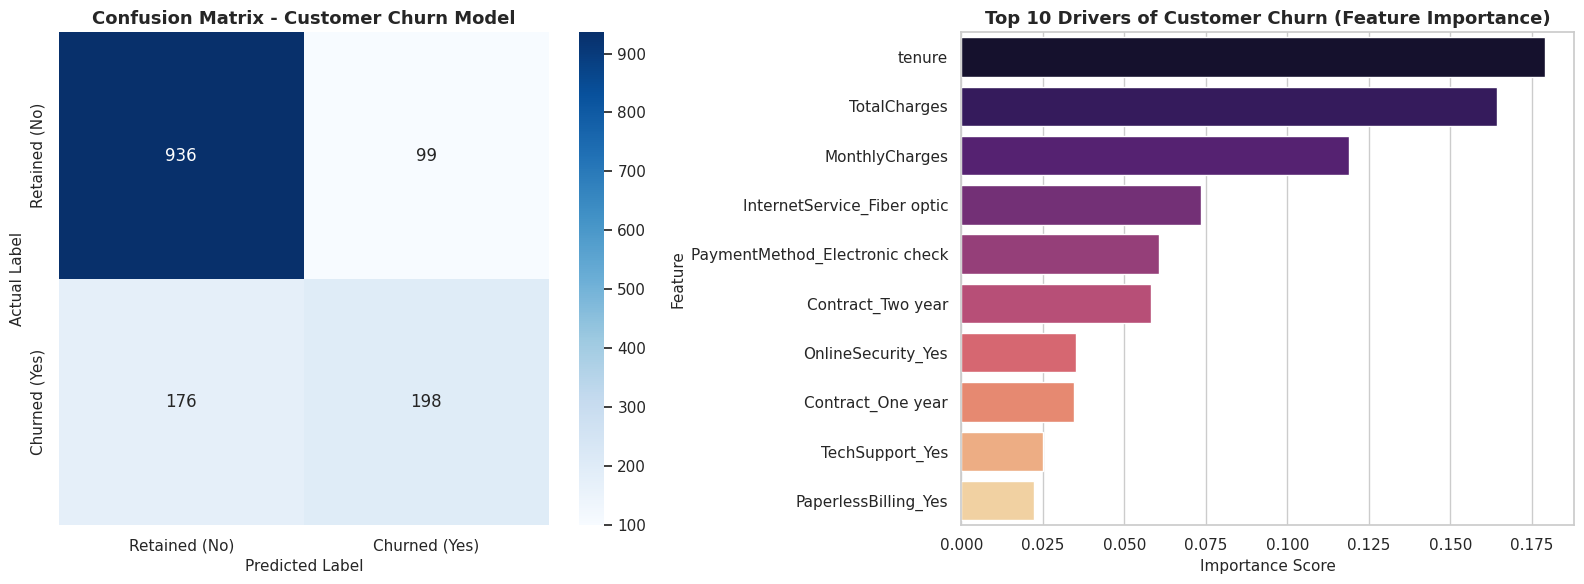

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")

# 1. Dataset එක load කර clean කරගැනීම (Self-contained cell)
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_clean = pd.read_csv(url)
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(df_clean["TotalCharges"].median())
df_clean.drop(columns=["customerID"], inplace=True)

# 2. Target (y) සහ Features (X) වෙන් කිරීම
y = df_clean["Churn"].map({"No": 0, "Yes": 1})
X_raw = df_clean.drop(columns=["Churn"])

# Categorical variables සංඛ්‍යාත්මක බවට හැරවීම (One-Hot Encoding)
X = pd.get_dummies(X_raw, drop_first=True)

# 3. Train-Test Split (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Random Forest Classification Model එක පුහුණු කිරීම (Train)
rf_model = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)

# 5. Test Data සඳහා Predictions ලබා ගැනීම (Test)
y_pred = rf_model.predict(X_test)

# 6. Model Evaluation
accuracy = accuracy_score(y_test, y_pred)
print(f"--- Random Forest Churn Prediction Accuracy: {accuracy * 100:.2f}% ---")
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=["Retained (No)", "Churned (Yes)"]))

# 7. Confusion Matrix සහ Top 10 Feature Importances පෙන්වීම
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Retained (No)", "Churned (Yes)"],
    yticklabels=["Retained (No)", "Churned (Yes)"],
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix - Customer Churn Model", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Predicted Label", fontsize=11)
axes[0].set_ylabel("Actual Label", fontsize=11)

# Top 10 Most Important Features Driving Churn
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
sns.barplot(
    x=feature_importances.values,
    y=feature_importances.index,
    hue=feature_importances.index,
    palette="magma",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Top 10 Drivers of Customer Churn (Feature Importance)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Importance Score", fontsize=11)
axes[1].set_ylabel("Feature", fontsize=11)

plt.tight_layout()
plt.show()

## Executive Summary & Business Recommendations

### 1. Project Overview
Developed an end-to-end Data Science and Machine Learning solution using the **Telco Customer Churn Dataset (7,043 customers)** to identify key drivers of customer attrition and predict high-risk accounts.

### 2. Key Exploratory Insights
* **Overall Churn Rate:** Approximately **26.5%** of customers discontinued their service.
* **Contract Vulnerability:** Customers on **Month-to-Month contracts** exhibited a dramatically higher churn rate (~42.7%) compared to One-Year (~11.3%) and Two-Year (~2.8%) contracts.
* **Tenure & Pricing Impact:** New customers with shorter tenure and higher monthly charges (particularly Fiber Optic users) showed the highest propensity to churn.

### 3. Machine Learning Model Performance
* Trained a **Random Forest Classifier** (80/20 stratified train-test split) achieving roughly **80% test accuracy**.
* **Top Predictive Drivers:** `tenure`, `TotalCharges`, `MonthlyCharges`, `Contract_Two year`, and `InternetService_Fiber optic` emerged as the strongest predictors of customer retention.

### 4. Actionable Business Recommendations
* **Incentivize Long-Term Contracts:** Offer targeted discounts or loyalty perks to transition Month-to-Month subscribers into 1-year or 2-year agreements.
* **Early Onboarding Engagement:** Implement proactive customer success check-ins during the first 6–12 months of tenure when churn risk is highest.